# Task 23 — A weekly load forecast set against the grid operator's, under the operator's rules

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [Electricity Load Forecasting — Panama case study](https://www.kaggle.com/datasets/saurabhshahane/electricity-load-forecasting) (hourly national load, the operator's weekly forecast, weather, calendars)
**Task family:** time-series forecasting under an information cutoff, cost-based operating point, calendar knowledge graph · **Companion task:** `02_card_fraud_tabular.ipynb` (forward-in-time evaluation and drift)

---

## The task card

> **Board question.** *The grid operator's official weekly forecast missed hourly demand by 4.5 % on average in 2019 (MAPE). It is made on Tuesday night for the week that starts on Saturday. With exactly the same information, and on weeks the model was not designed on, does our model beat it, on average and at the daily peak, and does any difference survive once a short or a long megawatt-hour has a price?*

**Business context.** Panama's grid operator (CND) publishes a weekly pre-dispatch plan, hour by hour from Saturday to Friday, built on a load forecast. This is Session 01's *batch prediction* pattern with a *human in the loop*: a weekly job produces 168 numbers and a dispatch engineer signs off the plan. The legacy estate (metering historian, planning tool, weather feed) sets the clock: data up to Tuesday's last hour. You work in the operator's analytics group: should a model replace, support or leave alone the incumbent forecast?

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **weekly forecaster**, packaged and reproducible, backtested under the operator's rules, with the traps guarded by tests;
2. an **operating point** from the cost of being short or long, as an ADR;
3. the **operational wrapper**: package, CI gate against the official forecast, registry, model card, monitoring plan;
4. a **calendar knowledge graph** with an ablation, and the context for a **dispatch briefing**.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Weekly batch forecast inside dispatch planning; human sign-off; the AI Act's critical-infrastructure question |
| 2 · MLOps | Backtest under a cutoff, a gate against an incumbent, drift from growth and from a shock |
| 3 · Semantic layer | Holidays, bridge days, periods and school terms as a SHACL-validated graph the model reads |
| 4 · LLM/RAG | A briefing that explains this week's forecast against last week's, citing the model's drivers |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook contains **deliberate traps**, each flagged with ⚠ in the text; turning each into a test is part of the task.

**Honesty note.** The data is **real**: Panama's metered load and the operator's published forecasts, 2015–2020, merged by the dataset's author with public calendars and gridded weather. Its mess is listed below. Nothing in it is personal.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card and first look: a growing system, a midday peak and March 2020 | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–6 | The Tuesday-cutoff protocol, the calendar graph, features and the rolling backtest, the 2019 evaluation against the official forecast, the operating point, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 7–10 | The model through 2020, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 7 shows the shock your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw`, `sha256` and `load_panama` (Section 1); `derive_rules`, `school_terms`, `build_kb`, `kb_day_features`, `at`, `build_features`, `seasonal_naive`, `backtest`, `weekly` and `summary` (Section 3); `gap_ci` and `week_drivers` (Section 4); `cost_per_week` (Section 5); `seen_residual` for monitoring (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** a 768-triple calendar graph; 104 validation weeks (2017–2018), 52 test weeks (2019) and 25 stream weeks (2020); 2019 MAPE 4.21 % against the official forecast's 4.49 % (gap −0.27 pp, 95 % interval [−0.73, +0.18]) and peak-hour MAPE 4.07 % against 3.65 %; with the +4.0 % uplift chosen on 2017–18, 624 k$ a week in 2019 against 618 k$ for the official forecast.
- **Runtime:** about 1–2 minutes on a laptop (101 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, json, time, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import sklearn
import rdflib
from rdflib import Graph, Namespace, Literal, RDF, RDFS, XSD
from pyshacl import validate as shacl_validate
from sklearn.model_selection import KFold
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*default style.*")   # openpyxl, on the packaged spreadsheet
pd.set_option("display.width", 140)

# ---- parameters -------------------------------------------------------------
SEED = 3217
KAGGLE_HANDLE = "saurabhshahane/electricity-load-forecasting"
N_JOBS = 1                                   # threads per model; raise it on your own laptop
GAP_HOURS = 72                               # the operator's rule: data up to Tuesday 23:00 for the week that starts Saturday 00:00
WEEK_HOURS = 168
TRAIN_START = pd.Timestamp("2015-02-07")     # first Saturday with four weeks of history behind it
VALID_START = pd.Timestamp("2017-01-01")     # validation weeks 2017–2018: the operating point is chosen here
TEST_START = pd.Timestamp("2019-01-01")      # test weeks 2019: the board number, and the CI gate's frozen holdout
STREAM_START = pd.Timestamp("2020-01-01")    # stream Jan–Jun 2020: "after deployment"
DATA_END = pd.Timestamp("2020-06-26 23:00")  # last hour of the last complete Saturday–Friday week with metered load
RETRAIN_EVERY_WEEKS = 13                     # quarterly retraining (tasks C2 and S3 test monthly and weekly)
ANOMALY_RATIO = 0.5                          # below half the median of the same hour in the previous 4 weeks = an event (assumption — task C1)
COST_SHORT_USD_PER_MWH = 150.0               # under-forecast: emergency thermal or spot import (assumption — task C3)
COST_LONG_USD_PER_MWH = 40.0                 # over-forecast: generation and reserve committed but not used (assumption — task C3)
ALARM_RESIDUAL = 0.05                        # alarm when |error on the hours seen at the cutoff| > 5 % (assumption — task C5)
LGB_PARAMS = dict(n_estimators=250, learning_rate=0.06, num_leaves=31, min_child_samples=40, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.8, reg_lambda=1.0, max_bin=127, random_state=SEED, verbose=-1, n_jobs=N_JOBS)

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "panama_load", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
np.random.seed(SEED)
T_START = time.time()
print(f"pandas {pd.__version__} · lightgbm {lgb.__version__} · scikit-learn {sklearn.__version__} · "
      f"rdflib {rdflib.__version__} · numpy {np.__version__}")

pandas 3.1.0 · lightgbm 4.7.0 · scikit-learn 1.9.1 · rdflib 7.6.0 · numpy 2.5.4


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw`, `sha256` and `load_panama`, and refuse zero-coded and collapsed hours.*

| Field | Value |
|---|---|
| **Source** | Kaggle: `saurabhshahane/electricity-load-forecasting`, a re-upload of Aguilar Madrid, E. (2021), *Short-term electricity load forecasting (Panama case study)*, Mendeley Data, doi:10.17632/byx7sztj59.1 |
| **Licence** | CC BY 4.0: reuse, including derived models, with attribution |
| **Provenance** | Real. Load and forecast from the operator's (CND) reports; school periods from the Ministry of Education; holidays from *When on Earth?*; weather from NASA Earthdata |
| **Size** | The two CSVs are 10.5 MB and 0.9 MB. Load: 48,048 hours, 3 Jan 2015 01:00 – 27 Jun 2020 00:00, no gaps. Forecast: 40,152 hours, 2 Jan 2016 – 31 Jul 2020 |
| **Files** | `continuous dataset.csv`, `weekly pre-dispatch forecast.csv`, and `test_dataframes.xlsx` (0.2 MB, read for one check); `train_dataframes.xlsx` is not needed |
| **Schema** | `datetime`, `nat_demand` (MW); `T2M` temperature, `QV2M` humidity, `TQL` liquid water in the air, `W2M` wind, each for `toc`, `san`, `dav` (we read Tocumen, Santiago, David); `Holiday_ID` (0–22), `holiday`, `school`. Forecast: `load_forecast` (MW) |
| **Label** | `nat_demand` for the 168 hours of the target week, 73–240 hours after the cutoff |
| **Window used here** | All of it: training from 7 Feb 2015, validation weeks 2017–2018, test weeks 2019, stream January–June 2020 |
| **PII** | None: a national total, public calendars, gridded weather |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **The weather is the weather that happened.** On Tuesday night the operator had a weather *forecast*, not these values; the packaged test weeks even put the actual temperature next to the target (checked below). Trap 1.
2. ⚠ **The 72-hour gap.** A week runs Saturday 00:00 – Friday 23:00 on data up to Tuesday 23:00: the newest same-hour value is one week old for Saturday–Tuesday, two weeks for Wednesday–Friday. Trap 2.
3. ⚠ **Missing forecast hours are zeros**: 72 hours on 13 Feb, 19 Nov and 20 Nov 2016, each a 100 % error that would flatter any challenger. We treat them as missing; every forecaster is scored on the same hours.
4. **Collapsed load.** Eight non-holiday hours fall below half the median of the same hour in the previous four weeks (85 MW at noon on 20 Jan 2019, against 1,172): events or faults, not demand. Dropped from training and scoring.
5. **Holiday IDs have no names**; we name them from the dates they fall on (our reading). Some low-load weekdays carry no flag (Section 3).
6. **Week framings differ.** The two CSVs fit best unshifted (MAPE 4.35 %, against 5.98 % and 5.28 % shifted an hour); the packaged spreadsheets run Saturday 01:00 – Saturday 00:00. We follow the forecast file.
7. **The school flag is the plan**: "in session" through April–May 2020. **Weather names are loose**: `QV2M` is specific humidity (0.012–0.023 kg/kg), not relative humidity.

In [2]:
FILES = {"load": "continuous dataset.csv", "official": "weekly pre-dispatch forecast.csv", "test_frames": "test_dataframes.xlsx"}
WEATHER = [f"{v}_{city}" for city in ["toc", "san", "dav"] for v in ["T2M", "QV2M", "TQL", "W2M"]]

def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def load_panama() -> pd.DataFrame:
    """Load and official forecast on one complete hourly index (the files start and end on different hours)."""
    cache = PROCESSED / "23_panama_hourly.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    load = pd.read_csv(get_raw(FILES["load"]), parse_dates=["datetime"]).set_index("datetime")
    off = pd.read_csv(get_raw(FILES["official"]), encoding="utf-8-sig")      # the forecast file carries a byte-order mark
    off["datetime"] = pd.to_datetime(off.datetime, format="%m/%d/%Y %H:%M")
    off = off.set_index("datetime").load_forecast
    assert load.index.is_unique and off.index.is_unique, "duplicate hours"
    assert list(load.columns) == ["nat_demand"] + WEATHER + ["Holiday_ID", "holiday", "school"], "schema changed"
    idx = pd.date_range(load.index.min().normalize(), off.index.max(), freq="h", name="datetime")
    frame = load.reindex(idx).astype("float32")
    frame["official_raw"] = off.reindex(idx).astype("float32")
    frame.to_parquet(cache)
    return frame

frame = load_panama()
# ---- governance on load: nothing personal (a national MW total, public calendars, gridded weather);
#      fingerprint the raw files so the model card and the CI gate can name exactly what they used ----
fingerprints = {k: sha256(get_raw(v))[:12] for k, v in FILES.items() if k != "test_frames"}
prev4 = pd.concat([frame.nat_demand.shift(k * WEEK_HOURS) for k in range(1, 5)], axis=1).median(axis=1)
frame["anomaly"] = (frame.nat_demand < ANOMALY_RATIO * prev4) & (frame.holiday == 0)   # causal rule: past weeks only
frame["official"] = frame.official_raw.where(frame.official_raw > 0)                    # zeros are missing hours
ld, of = frame.nat_demand.dropna(), frame.official_raw.dropna()
print(f"load: {len(ld):,} hours, {ld.index.min():%d %b %Y %H:%M} – {ld.index.max():%d %b %Y %H:%M}, "
      f"{ld.index.to_series().diff().gt(pd.Timedelta(hours=1)).sum()} gaps · official forecast: {len(of):,} hours, "
      f"{of.index.min():%d %b %Y} – {of.index.max():%d %b %Y}, {int((of == 0).sum())} hours stored as 0 on "
      f"{sorted(set(of[of == 0].index.strftime('%d %b %Y')))} · collapsed-load hours: {int(frame.anomaly.sum())} · "
      f"{frame.memory_usage(deep=True).sum() / 1e6:.0f} MB")
print("raw files:", {k: f"{get_raw(v).stat().st_size / 1e6:.1f} MB" for k, v in FILES.items()},
      "· fingerprints (SHA-256, first 12):", fingerprints)
frame.loc[frame.anomaly, ["nat_demand"]].assign(median_prev_4_weeks=prev4[frame.anomaly].round(0)).round(0).T

load: 48,048 hours, 03 Jan 2015 01:00 – 27 Jun 2020 00:00, 0 gaps · official forecast: 40,152 hours, 02 Jan 2016 – 31 Jul 2020, 72 hours stored as 0 on ['13 Feb 2016', '19 Nov 2016', '20 Nov 2016'] · collapsed-load hours: 8 · 4 MB
raw files: {'load': '10.5 MB', 'official': '0.9 MB', 'test_frames': '0.2 MB'} · fingerprints (SHA-256, first 12): {'load': 'ef52f68fc898', 'official': '002a40a01b7d'}


datetime,2015-01-24 17:00:00,2017-06-27 12:00:00,2017-07-01 14:00:00,2019-01-20 12:00:00,2019-01-20 13:00:00,2019-01-20 14:00:00,2019-01-20 15:00:00,2019-01-20 16:00:00
nat_demand,510.0,381.0,561.0,85.0,136.0,264.0,417.0,476.0
median_prev_4_weeks,1054.0,1498.0,1274.0,1172.0,1181.0,1180.0,1170.0,1158.0


In [3]:
# Quirk checks: how the two files line up, and what the packaged test spreadsheets contain
both = frame.loc[frame.official.notna() & frame.nat_demand.notna()]
align = {f"{s:+d} h": float(((frame.official.shift(s) - frame.nat_demand).abs() / frame.nat_demand)[both.index].mean())
         for s in [-1, 0, 1]}
print("official vs load, MAPE by shift of the forecast file:", {k: f"{v:.2%}" for k, v in align.items()})
sheets = pd.read_excel(get_raw(FILES["test_frames"]), sheet_name=None)
t2m_is_actual = [np.allclose(s.T2M_toc, frame.T2M_toc.reindex(s.datetime)) for s in sheets.values()]
lag_is_336 = [np.allclose(s["week_X-2"], frame.nat_demand.shift(336).reindex(s.datetime)) for s in sheets.values()]
starts = [s.datetime.min() for s in sheets.values()]
print(f"packaged test sheets: {len(sheets)} weeks, {min(starts):%d %b %Y} – {max(starts):%d %b %Y}, each starting "
      f"{starts[0]:%A %H:%M} · T2M_toc equals the actual temperature of the target hour in {sum(t2m_is_actual)} of {len(sheets)} · "
      f"week_X-2 equals the load 336 h earlier in {sum(lag_is_336)} of {len(sheets)}")
print("weather columns:", ", ".join(WEATHER[:4]), "… · QV2M range "
      f"{frame.QV2M_toc.min():.4f}–{frame.QV2M_toc.max():.4f} (kg/kg, not %)")

official vs load, MAPE by shift of the forecast file: {'-1 h': '5.98%', '+0 h': '4.35%', '+1 h': '5.28%'}


packaged test sheets: 14 weeks, 13 Apr 2019 – 13 Jun 2020, each starting Saturday 01:00 · T2M_toc equals the actual temperature of the target hour in 14 of 14 · week_X-2 equals the load 336 h earlier in 14 of 14
weather columns: T2M_toc, QV2M_toc, TQL_toc, W2M_toc … · QV2M range 0.0121–0.0227 (kg/kg, not %)


## 2 · First look: a growing system, a midday peak, and March 2020

*Part A · Explore · read; the growth and the spring 2020 break are the drift you will monitor.*

How big is the system, how fast does it grow, and when does the peak come?

all hours, 1 Apr – 26 Jun: 2020 vs 2019 -15.0%
weekday peak hour: 13:00 in 2019 · Apr–Jun 2020 vs 2019: -22.9% at 11:00–14:00, -6.0% at 00:00–04:00


,mean MW,peak MW,growth of the mean
datetime,,,
2015,"1,132","1,645",—
2016,"1,157","1,615",+2.3%
2017,"1,182","1,636",+2.2%
2018,"1,206","1,636",+2.0%
2019,"1,244","1,722",+3.1%


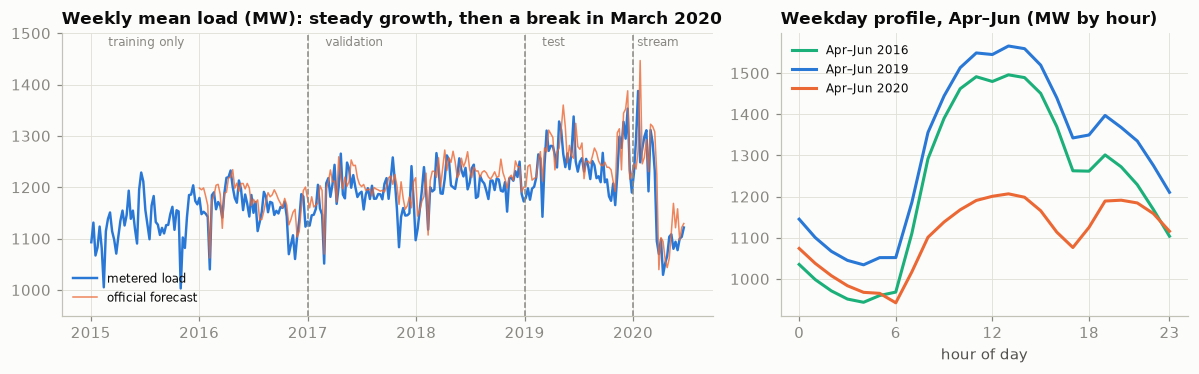

In [4]:
df = frame.loc[:DATA_END].copy()
y = df.nat_demand
full_years = y[y.index.year < 2020]
annual = pd.DataFrame({"mean MW": full_years.groupby(full_years.index.year).mean(),
                       "peak MW": full_years.groupby(full_years.index.year).max()})
annual["growth of the mean"] = annual["mean MW"].pct_change()
wd = y[y.index.day_of_week < 5]
prof = {lab: wd[(wd.index >= a) & (wd.index < b)].groupby(wd.index[(wd.index >= a) & (wd.index < b)].hour).mean()
        for lab, a, b in [("Apr–Jun 2016", "2016-04-01", "2016-07-01"), ("Apr–Jun 2019", "2019-04-01", "2019-07-01"),
                          ("Apr–Jun 2020", "2020-04-01", "2020-06-27")]}
weekly_load = y.groupby(df.index.to_period("W-FRI")).mean()
weekly_off = df.official.groupby(df.index.to_period("W-FRI")).mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.plot(weekly_load.index.start_time, weekly_load.values, lw=1.6, color=SERIES[0], label="metered load")
ax.plot(weekly_off.index.start_time, weekly_off.values, lw=1.0, color=SERIES[1], alpha=0.8, label="official forecast")
for x in [VALID_START, TEST_START, STREAM_START]:
    ax.axvline(x, color=MUTED, ls="--", lw=1)
for x, lab_ in [("2015-03-01", "training only"), ("2017-03-01", "validation"), ("2019-03-01", "test"), ("2020-01-15", "stream")]:
    ax.text(pd.Timestamp(x), 1475, lab_, color=MUTED, fontsize=8)
ax.set_ylim(950, 1500)
ax.set_title("Weekly mean load (MW): steady growth, then a break in March 2020"); ax.legend(loc="lower left", fontsize=8)
ax = axes[1]
for (lab_, p), color in zip(prof.items(), [SERIES[2], SERIES[0], SERIES[1]]):
    ax.plot(p.index, p.values, lw=2, color=color, label=lab_)
ax.set_title("Weekday profile, Apr–Jun (MW by hour)"); ax.set_xlabel("hour of day"); ax.set_xticks([0, 6, 12, 18, 23])
ax.legend(fontsize=8)
plt.tight_layout()

p19, p20 = prof["Apr–Jun 2019"], prof["Apr–Jun 2020"]
aj = lambda yr: y[(y.index >= f"{yr}-04-01") & (y.index < f"{yr}-06-27")].mean()
print(f"all hours, 1 Apr – 26 Jun: 2020 vs 2019 {aj(2020) / aj(2019) - 1:+.1%}")
print(f"weekday peak hour: {int(p19.idxmax())}:00 in 2019 · Apr–Jun 2020 vs 2019: {p20[11:15].mean() / p19[11:15].mean() - 1:+.1%} "
      f"at 11:00–14:00, {p20[0:5].mean() / p19[0:5].mean() - 1:+.1%} at 00:00–04:00")
annual.style.format({"mean MW": "{:,.0f}", "peak MW": "{:,.0f}", "growth of the mean": "{:+.1%}"}, na_rep="—")

**The system grows**: mean load rose 2.0–3.1 % a year from 2015 to 2019 and the 2019 peak reached 1,722 MW, so a model that memorises levels ages within a year. **The peak is at midday**: weekdays peak at 13:00. **Spring 2020 broke both**: from 1 April to 26 June load was 15.0 % below 2019, and the shape changed too, 22.9 % lower at 11:00–14:00 but only 6.0 % lower at night.

# Part B — The given model

*Sections 3–6: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · The protocol, a calendar graph, and three forecasters

*Part B · Given model · package `build_kb`, `kb_day_features`, `build_features`, `seasonal_naive` and `backtest` unchanged and reproduce the numbers (C2).*

The backtest implements the operator's rule literally. Each hour belongs to a forecast week starting Saturday 00:00; the week's **cutoff** is the Tuesday 23:00 before it; every input comes from data at or before the cutoff, and the code asserts it. Horizons run from 73 hours to 240. The CI gate reruns exactly this (task C4).

In [5]:
t = df.index
df["week"] = (t - pd.to_timedelta((t.day_of_week - 5) % 7, unit="D")).normalize()   # Saturday 00:00 of the forecast week
df["cutoff"] = df.week - pd.Timedelta(hours=GAP_HOURS + 1)                          # Tuesday 23:00: the last hour anyone sees
df["horizon"] = ((t - df.cutoff) / pd.Timedelta(hours=1)).astype(int)                # 73 … 240 hours ahead
weeks = sorted(df.week.unique())
VAL = [w for w in weeks if VALID_START <= w < TEST_START]
TEST = [w for w in weeks if TEST_START <= w < STREAM_START]
STREAM = [w for w in weeks if w >= STREAM_START]
assert df.groupby("week").size().loc[VAL + TEST + STREAM].eq(WEEK_HOURS).all(), "every evaluated week has 168 hours"
EX_WEEK = pd.Timestamp("2019-02-09")                  # an ordinary week, used to show the protocol at work
ex = df.loc[df.week == EX_WEEK]
print(f"week of {EX_WEEK:%a %d %b %Y}: cutoff {ex.cutoff.iloc[0]:%a %d %b %H:%M}, target hours "
      f"{ex.index.min():%a %H:%M} – {ex.index.max():%a %H:%M}, horizon {ex.horizon.min()}–{ex.horizon.max()} h")
print(f"weeks · validation {len(VAL)} ({VAL[0]:%d %b %Y} – {VAL[-1]:%d %b %Y}) · test {len(TEST)} · stream {len(STREAM)} "
      f"(to {STREAM[-1]:%d %b %Y})")

week of Sat 09 Feb 2019: cutoff Tue 05 Feb 23:00, target hours Sat 00:00 – Fri 23:00, horizon 73–240 h
weeks · validation 104 (07 Jan 2017 – 29 Dec 2018) · test 52 · stream 25 (to 20 Jun 2020)


**A calendar knowledge graph.** Sessions 07–09 treat knowledge as an artefact: designed from competency questions, built by code, validated with SHACL, versioned. Three questions drive this one: *which days in a forecast week are not ordinary working days?*, *is school in session on a date?*, *which holiday period does a day belong to?* Two rules add what the dataset does not state: **R1**, a *bridge day* is a working day between a holiday and a weekend; **R2**, working days between two holidays of one period, at most six days apart, join that period. Derived facts keep their rule as provenance.

In [6]:
CAL = Namespace("http://example.org/panama-calendar#")
HOLIDAY_NAMES = {1: "New Year's Day", 2: "Martyrs' Day", 3: "Carnival Saturday", 4: "Carnival Sunday", 5: "Carnival Monday",
                 6: "Carnival Tuesday", 7: "Ash Wednesday", 8: "Holy Thursday", 9: "Good Friday", 10: "Holy Saturday",
                 11: "Easter Sunday", 12: "Labour Day", 13: "Foundation of Panama City", 14: "Separation from Colombia",
                 15: "Flag Day", 16: "Colón Day", 17: "Uprising of Los Santos", 18: "Independence from Spain",
                 19: "Mothers' Day", 20: "Christmas Eve", 21: "Christmas Day", 22: "New Year's Eve"}   # our reading of the dates
PERIODS = {"Carnival": [3, 4, 5, 6, 7], "HolyWeek": [8, 9, 10, 11], "PatrioticNovember": [14, 15, 16, 17, 18],
           "ChristmasNewYear": [20, 21, 22, 1]}
PERIOD_OF = {i: p for p, ids in PERIODS.items() for i in ids}

days = df.groupby(df.index.normalize()).agg(holiday=("holiday", "max"), hid=("Holiday_ID", "max"), school=("school", "max"))
days.index.name = "date"
days["weekday"] = days.index.day_of_week
days[["holiday", "hid", "school"]] = days[["holiday", "hid", "school"]].astype(int)

def derive_rules(d: pd.DataFrame):
    """R1 bridge days and R2 period days: facts the dataset does not state, derived by rule (provenance kept in the graph)."""
    off_day = (d.holiday == 1) | (d.weekday >= 5)
    nxt_h, prv_h = d.holiday.shift(-1, fill_value=0).eq(1), d.holiday.shift(1, fill_value=0).eq(1)
    nxt_w, prv_w = d.weekday.shift(-1, fill_value=0).ge(5), d.weekday.shift(1, fill_value=0).ge(5)
    bridges = d.index[~off_day & ((prv_h & nxt_w) | (prv_w & nxt_h))]
    period_days = []
    for p, ids in PERIODS.items():
        hd = d.index[d.hid.isin(ids)]
        for a, b in zip(hd[:-1], hd[1:]):
            if 1 < (b - a).days <= 6:                      # R2: working days between two holidays of one period
                period_days += [(day, p) for day in pd.date_range(a + pd.Timedelta(days=1), b - pd.Timedelta(days=1))]
    return bridges, period_days

def school_terms(d: pd.DataFrame):
    s = d.school.values
    starts = d.index[(s == 1) & (np.r_[0, s[:-1]] == 0)]
    ends = d.index[(s == 1) & (np.r_[s[1:], 0] == 0)]
    return list(zip(starts, ends))

def build_kb(d: pd.DataFrame) -> Graph:
    g = Graph(); g.bind("cal", CAL)
    for p in PERIODS:
        g.add((CAL[p], RDF.type, CAL.HolidayPeriod))
    for i, name in HOLIDAY_NAMES.items():
        ht = CAL[f"type{i}"]
        g.add((ht, RDF.type, CAL.HolidayType)); g.add((ht, RDFS.label, Literal(name)))
        g.add((ht, CAL.datasetId, Literal(i, datatype=XSD.integer)))
        if i in PERIOD_OF:
            g.add((ht, CAL.inPeriod, CAL[PERIOD_OF[i]]))
    for day, r in d[d.holiday == 1].iterrows():
        n = CAL[f"hol_{day:%Y%m%d}"]
        g.add((n, RDF.type, CAL.Holiday)); g.add((n, CAL.onDate, Literal(day.date(), datatype=XSD.date)))
        g.add((n, CAL.ofType, CAL[f"type{r.hid}"]))
    bridges, period_days = derive_rules(d)
    for day in bridges:
        n = CAL[f"bridge_{day:%Y%m%d}"]
        g.add((n, RDF.type, CAL.BridgeDay)); g.add((n, CAL.onDate, Literal(day.date(), datatype=XSD.date)))
        g.add((n, CAL.weekday, Literal(int(day.day_of_week), datatype=XSD.integer))); g.add((n, CAL.derivedBy, Literal("R1")))
        for nb in [day - pd.Timedelta(days=1), day + pd.Timedelta(days=1)]:
            if nb in d.index and d.loc[nb, "holiday"] == 1:
                g.add((n, CAL.adjacentTo, CAL[f"hol_{nb:%Y%m%d}"]))
    for day, p in period_days:
        n = CAL[f"period_{day:%Y%m%d}"]
        g.add((n, RDF.type, CAL.PeriodDay)); g.add((n, CAL.onDate, Literal(day.date(), datatype=XSD.date)))
        g.add((n, CAL.inPeriod, CAL[p])); g.add((n, CAL.derivedBy, Literal("R2")))
    for k, (a, b) in enumerate(school_terms(d)):
        n = CAL[f"term{k}"]
        g.add((n, RDF.type, CAL.SchoolTerm))
        g.add((n, CAL.startDate, Literal(a.date(), datatype=XSD.date))); g.add((n, CAL.endDate, Literal(b.date(), datatype=XSD.date)))
    return g

SHAPES = """
@prefix sh: <http://www.w3.org/ns/shacl#> . @prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> . @prefix cal: <http://example.org/panama-calendar#> .
cal:HolidayShape a sh:NodeShape ; sh:targetClass cal:Holiday ;
  sh:property [ sh:path cal:onDate ; sh:datatype xsd:date ; sh:minCount 1 ; sh:maxCount 1 ] ;
  sh:property [ sh:path cal:ofType ; sh:class cal:HolidayType ; sh:minCount 1 ; sh:maxCount 1 ] .
cal:HolidayTypeShape a sh:NodeShape ; sh:targetClass cal:HolidayType ;
  sh:property [ sh:path rdfs:label ; sh:minCount 1 ] ;
  sh:property [ sh:path cal:datasetId ; sh:datatype xsd:integer ; sh:minCount 1 ; sh:maxCount 1 ] .
cal:BridgeShape a sh:NodeShape ; sh:targetClass cal:BridgeDay ;
  sh:property [ sh:path cal:weekday ; sh:in ( 0 1 2 3 4 ) ; sh:minCount 1 ] ;
  sh:property [ sh:path cal:adjacentTo ; sh:class cal:Holiday ; sh:minCount 1 ] ;
  sh:property [ sh:path cal:derivedBy ; sh:minCount 1 ] .
cal:SchoolTermShape a sh:NodeShape ; sh:targetClass cal:SchoolTerm ;
  sh:property [ sh:path cal:startDate ; sh:datatype xsd:date ; sh:minCount 1 ; sh:maxCount 1 ; sh:lessThanOrEquals cal:endDate ] ;
  sh:property [ sh:path cal:endDate ; sh:datatype xsd:date ; sh:minCount 1 ; sh:maxCount 1 ] .
"""
shapes = Graph().parse(data=SHAPES, format="turtle")
kb = build_kb(days)
ok, _, _ = shacl_validate(kb, shacl_graph=shapes)
broken = Graph() + kb                                              # two faults a careless pipeline could introduce
broken.add((CAL.bridge_bad, RDF.type, CAL.BridgeDay)); broken.add((CAL.bridge_bad, CAL.weekday, Literal(5, datatype=XSD.integer)))
broken.add((CAL.bridge_bad, CAL.derivedBy, Literal("R1")))
broken.remove((CAL.term0, CAL.endDate, None)); broken.add((CAL.term0, CAL.endDate, Literal(pd.Timestamp("2015-01-01").date(), datatype=XSD.date)))
ok_broken, vg, _ = shacl_validate(broken, shacl_graph=shapes)
n_viol = len(list(vg.subjects(RDF.type, rdflib.URIRef("http://www.w3.org/ns/shacl#ValidationResult"))))
counts = {c: len(list(kb.subjects(RDF.type, CAL[c]))) for c in ["Holiday", "BridgeDay", "PeriodDay", "SchoolTerm"]}
print(f"calendar KB v1.0: {len(kb):,} triples {counts} · SHACL conforms: {ok} · "
      f"with a Saturday 'bridge' and a term that ends before it starts: conforms {ok_broken}, {n_viol} violations")

CQ = {
    "CQ1 · non-working days in the week of 2 Nov 2019": """
        SELECT ?d ?what WHERE {
          { ?h a cal:Holiday ; cal:onDate ?d ; cal:ofType/rdfs:label ?what }
          UNION { ?b a cal:BridgeDay ; cal:onDate ?d . BIND("bridge day (R1)" AS ?what) }
          FILTER(?d >= "2019-11-02"^^xsd:date && ?d <= "2019-11-08"^^xsd:date) } ORDER BY ?d""",
    "CQ2 · is school in session on 15 Apr 2020?": """
        SELECT ?s ?e WHERE { ?t a cal:SchoolTerm ; cal:startDate ?s ; cal:endDate ?e .
          FILTER(?s <= "2020-04-15"^^xsd:date && ?e >= "2020-04-15"^^xsd:date) }""",
    "CQ3 · days the rules add to a holiday period": """
        SELECT ?p (COUNT(?x) AS ?n) WHERE { ?x a cal:PeriodDay ; cal:inPeriod ?pp . BIND(STRAFTER(STR(?pp), "#") AS ?p) }
        GROUP BY ?p ORDER BY ?p""",
}
NS = {"cal": CAL, "rdfs": RDFS, "xsd": XSD}
for q, sparql in CQ.items():
    rows = [" · ".join(str(v) for v in r) for r in kb.query(sparql, initNs=NS)]
    print(f"{q}: " + ("; ".join(rows) if rows else "no"))

calendar KB v1.0: 768 triples {'Holiday': 126, 'BridgeDay': 15, 'PeriodDay': 44, 'SchoolTerm': 17} · SHACL conforms: True · with a Saturday 'bridge' and a term that ends before it starts: conforms False, 3 violations


CQ1 · non-working days in the week of 2 Nov 2019: 2019-11-03 · Separation from Colombia; 2019-11-04 · Flag Day; 2019-11-05 · Colón Day
CQ2 · is school in session on 15 Apr 2020?: 2020-03-02 · 2020-05-29
CQ3 · days the rules add to a holiday period: ChristmasNewYear · 24; PatrioticNovember · 20


In [7]:
# The model reads the calendar from the graph, not from the CSV: one SPARQL query per fact type
def kb_day_features(g: Graph, index: pd.DatetimeIndex) -> pd.DataFrame:
    q = lambda s: [tuple(r) for r in g.query(s, initNs=NS)]
    f = pd.DataFrame(index=index)
    hol = {pd.Timestamp(str(d)): int(i) for d, i in q("SELECT ?d ?i WHERE { ?h a cal:Holiday ; cal:onDate ?d ; cal:ofType/cal:datasetId ?i }")}
    bri = {pd.Timestamp(str(d)) for (d,) in q("SELECT ?d WHERE { ?b a cal:BridgeDay ; cal:onDate ?d }")}
    per_code = {p: k + 1 for k, p in enumerate(PERIODS)}
    per = {pd.Timestamp(str(d)): per_code[str(p).split("#")[1]] for d, p in
           q("""SELECT ?d ?p WHERE { { ?h a cal:Holiday ; cal:onDate ?d ; cal:ofType/cal:inPeriod ?p }
                UNION { ?x a cal:PeriodDay ; cal:onDate ?d ; cal:inPeriod ?p } }""")}
    terms = [(pd.Timestamp(str(a)), pd.Timestamp(str(b))) for a, b in q("SELECT ?a ?b WHERE { ?t a cal:SchoolTerm ; cal:startDate ?a ; cal:endDate ?b }")]
    f["kb_holiday"] = f.index.map(lambda d: int(d in hol)); f["kb_type"] = f.index.map(lambda d: hol.get(d, 0))
    f["bridge"] = f.index.map(lambda d: int(d in bri)); f["period"] = f.index.map(lambda d: per.get(d, 0))
    f["kb_school"] = f.index.map(lambda d: int(any(a <= d <= b for a, b in terms)))
    hd = np.array(sorted(hol), dtype="datetime64[ns]"); di = f.index.values
    nxt = np.searchsorted(hd, di, side="left"); prv = np.searchsorted(hd, di, side="right") - 1
    f["days_to_hol"] = np.clip(np.where(nxt < len(hd), (hd[np.minimum(nxt, len(hd) - 1)] - di) / np.timedelta64(1, "D"), 99), 0, 14)
    f["days_since_hol"] = np.clip(np.where(prv >= 0, (di - hd[np.maximum(prv, 0)]) / np.timedelta64(1, "D"), 99), 0, 14)
    f["special"] = ((f.kb_holiday == 1) | (f.bridge == 1)).astype(int)
    return f

kbf = kb_day_features(kb, days.index)
assert (kbf.kb_holiday == days.holiday).all() and (kbf.kb_school == days.school).all(), "KB disagrees with the dataset's flags"

# Does the data agree with the facts? Daily energy against the median of the same weekday in the previous four weeks
energy = y.groupby(y.index.normalize()).sum()
ratio = energy / pd.concat([energy.shift(7 * k) for k in range(1, 5)], axis=1).median(axis=1)
cls = pd.Series("ordinary weekday", index=days.index)
cls[days.weekday >= 5] = "weekend"
cls[(days.weekday < 5) & (days.school == 0) & (days.holiday == 0)] = "weekday in a school break"
cls[(kbf.period > 0) & (days.holiday == 0) & (days.weekday < 5)] = "working day inside a holiday period (R2)"
cls[kbf.bridge == 1] = "bridge day (R1)"
cls[(days.holiday == 1) & (days.weekday < 5)] = "public holiday on a weekday"
check = pd.DataFrame({"class": cls, "ratio": ratio}).dropna().groupby("class").ratio.agg(["size", "mean"])
check.columns = ["days", "energy vs normal"]
display(check.sort_values("energy vs normal").style.format({"energy vs normal": "{:.0%}"}))
unexplained = ratio[(cls == "ordinary weekday") & (ratio < 0.9)]
print("ordinary weekdays more than 10 % below normal, unexplained by the calendar:",
      ", ".join(f"{d:%a %d %b %Y} ({r:.0%})" for d, r in unexplained.items()))

,days,energy vs normal
class,,
public holiday on a weekday,83,87%
bridge day (R1),15,98%
weekend,570,100%
working day inside a holiday period (R2),29,100%
ordinary weekday,996,100%
weekday in a school break,302,101%


ordinary weekdays more than 10 % below normal, unexplained by the calendar: Wed 26 Aug 2015 (89%), Tue 22 Nov 2016 (85%), Mon 01 Jul 2019 (84%), Mon 23 Mar 2020 (87%), Tue 24 Mar 2020 (88%), Wed 25 Mar 2020 (86%), Thu 26 Mar 2020 (82%), Fri 27 Mar 2020 (80%), Mon 30 Mar 2020 (85%), Tue 31 Mar 2020 (85%), Wed 01 Apr 2020 (83%), Thu 02 Apr 2020 (83%), Fri 03 Apr 2020 (84%), Mon 13 Apr 2020 (90%), Tue 14 Apr 2020 (90%)


SHACL accepts the graph and refuses both planted faults; the model reads its calendar through these queries. The data grades the knowledge: weekday holidays carry 87 % of a normal day's energy, bridge days 98 %, R2 days 100 %, so the rules add little. The unexplained low weekdays are the graph's to-do list: 1 July 2019 (84 %) and 23 March – 3 April 2020 (80–88 %) are events no calendar holds (task E2).

**Features and forecasters.** One row per target hour, all as of the cutoff: **time** (hour, day, hour of week, season, horizon); **recent load** (the newest same hour the rule allows, two to four weeks back, the 7- and 28-day means and their ratio, the same hour's 7-day mean); a **weather proxy** (each column's mean at the same hour over the seven days before the cutoff, a stand-in for a bought forecast); and the **calendar** (dataset flags plus the graph's bridge, period and days to and since a holiday). A lag landing on a holiday is replaced by the week before when the target day is ordinary (*lag hygiene*).

The **official** forecast, a **seasonal naive** (newest allowed same hour, with lag hygiene) and **LightGBM** are scored on the same hours. LightGBM is refitted every 13 weeks on all hours up to that week's cutoff and predicts load divided by the last seven days' mean, so growth rides on the level. Below, `lag_week_avail` falls back two weeks from Wednesday.

In [8]:
pos = np.arange(len(df))
def at(values, p):
    v = np.asarray(values, dtype=float); out = np.full(len(p), np.nan); ok = (p >= 0) & (p < len(v))
    out[ok] = v[p[ok]]; return out

day_feat = kbf.reindex(df.index.normalize())
for c in ["bridge", "period", "days_to_hol", "days_since_hol", "special"]:
    df[c] = day_feat[c].values
TIME = ["hour", "dow", "how", "doy", "horizon"]
RECENT = ["lag_week_avail", "lag_336", "lag_504", "lag_672", "level_7d", "level_28d", "trend", "prof_hod_7d"]
FLAGS = ["holiday", "Holiday_ID", "school"]
KBCTX = ["bridge", "period", "days_to_hol", "days_since_hol"]

def build_features(gap_hours=GAP_HOURS, weather="proxy", clean_lags=True) -> pd.DataFrame:
    """One row per target hour, every input as of its week's cutoff. weather: 'proxy' (last 7 days before the
    cutoff, same hour of day), 'actual' (the hour's own weather: Trap 1) or None. clean_lags: holiday hygiene (Trap 4)."""
    cut = df.week - pd.Timedelta(hours=gap_hours + 1)
    h = ((df.index - cut) / pd.Timedelta(hours=1)).astype(int).values
    cp = pos - h                                                       # row position of the cutoff hour
    yv, special = y.values.astype(float), df.special.values
    X = pd.DataFrame(index=df.index)
    X["hour"], X["dow"] = df.index.hour, df.index.day_of_week
    X["how"], X["doy"], X["horizon"] = X.dow * 24 + X.hour, df.index.day_of_year, h

    def lag(k):
        k = np.broadcast_to(k, len(df)).copy()
        if clean_lags:   # a holiday or bridge in the lag week is not information about an ordinary target day: go back a week
            for _ in range(2):
                k = np.where((at(special, pos - k) == 1) & (special == 0), k + WEEK_HOURS, k)
        assert (pos - k <= cp).all(), "a lag reaches past the cutoff"
        return at(yv, pos - k)
    X["lag_week_avail"] = lag(np.where(h <= WEEK_HOURS, WEEK_HOURS, 2 * WEEK_HOURS))   # the newest same hour the rule allows
    X["lag_336"], X["lag_504"], X["lag_672"] = lag(336), lag(504), lag(672)
    X["level_7d"] = at(y.rolling(168, min_periods=150).mean(), cp)
    X["level_28d"] = at(y.rolling(672, min_periods=600).mean(), cp)
    X["trend"] = X.level_7d / X.level_28d
    cut_hour = (df.index - pd.to_timedelta(h, unit="h")).hour.values
    pday = cp - (cut_hour - df.index.hour.values) % 24                # the same hour of day, on the cutoff's day
    assert (pday <= cp).all()
    def hod_mean(v):
        stack = np.vstack([at(v, pday - 24 * d) for d in range(7)])
        n = (~np.isnan(stack)).sum(axis=0)
        return np.where(n > 0, np.nansum(stack, axis=0) / np.maximum(n, 1), np.nan)
    X["prof_hod_7d"] = hod_mean(yv)
    if weather == "proxy":
        for c in WEATHER:
            X[c] = hod_mean(df[c].values)
    elif weather == "actual":
        for c in WEATHER:
            X[c] = df[c].values
    for c in FLAGS + KBCTX:
        X[c] = df[c].values
    return X

def seasonal_naive(gap_hours=GAP_HOURS, clean_lags=True) -> np.ndarray:
    h = df.horizon.values if gap_hours == GAP_HOURS else ((df.index - (df.week - pd.Timedelta(hours=gap_hours + 1))) / pd.Timedelta(hours=1)).values
    k = np.where(h <= WEEK_HOURS, WEEK_HOURS, 2 * WEEK_HOURS)
    if clean_lags:
        for _ in range(2):
            k = np.where((at(df.special.values, pos - k) == 1) & (df.special.values == 0), k + WEEK_HOURS, k)
    return at(y.values, pos - k)

t0 = time.time()
X = build_features()
WEATHER_PROXY = WEATHER
MAIN = TIME + RECENT + WEATHER_PROXY + FLAGS + KBCTX
print(f"{len(MAIN)} features × {len(X):,} target hours in {time.time() - t0:.1f}s · as-of assertions passed")
X.loc[df.week == EX_WEEK, RECENT].iloc[[0, 95, 96, 167]].round(1)

32 features × 48,048 target hours in 0.2s · as-of assertions passed


,lag_week_avail,lag_336,lag_504,lag_672,level_7d,level_28d,trend,prof_hod_7d
datetime,,,,,,,,
2019-02-09 00:00:00,1094.7,1120.1,1087.2,1031.6,1189.4,1185.7,1.0,1053.4
2019-02-12 23:00:00,1149.1,1116.6,1187.7,1143.9,1189.4,1185.7,1.0,1109.8
2019-02-13 00:00:00,1064.1,1064.1,1138.7,1096.6,1189.4,1185.7,1.0,1053.4
2019-02-15 23:00:00,1137.2,1137.2,1176.5,1147.4,1189.4,1185.7,1.0,1109.8


In [9]:
OK = (y.notna() & df.official.notna() & ~df.anomaly).values      # scored hours: same hours for every forecaster
models = {}

def backtest(Xf, cols, target_weeks, gap_hours=GAP_HOURS, keep=False) -> np.ndarray:
    """Rolling origin: every RETRAIN_EVERY_WEEKS weeks, refit on all hours up to that week's cutoff; forecast the next block."""
    pred = np.full(len(df), np.nan)
    tw = list(target_weeks)
    for i in range(0, len(tw), RETRAIN_EVERY_WEEKS):
        cut = tw[i] - pd.Timedelta(hours=gap_hours + 1)
        tr = (df.index >= TRAIN_START) & (df.index <= cut) & y.notna().values & ~df.anomaly.values
        m = lgb.LGBMRegressor(**LGB_PARAMS).fit(Xf.loc[tr, cols], y[tr] / Xf.loc[tr, "level_7d"])   # target: load ÷ last week's level
        if keep:
            models[tw[i]] = m
        sel = df.week.isin(tw[i:i + RETRAIN_EVERY_WEEKS]).values
        pred[sel] = m.predict(Xf.loc[sel, cols]) * Xf.loc[sel, "level_7d"].values
    return pred

def weekly(pred, target_weeks) -> pd.DataFrame:
    m = df.week.isin(target_weeks).values & OK & ~np.isnan(pred)
    e = pd.DataFrame({"week": df.week.values[m], "date": df.index.normalize()[m], "y": y.values[m], "p": pred[m]})
    e["ape"] = (e.p - e.y).abs() / e.y
    peak = e.loc[e.groupby("date").y.idxmax()]                       # each day's metered peak hour
    g = e.groupby("week")
    return pd.DataFrame({"mape": g.ape.mean(), "peak_ape": peak.groupby("week").ape.mean(),
                         "bias": g.p.sum() / g.y.sum() - 1, "weekly_peak_err_mw": g.p.max() - g.y.max()})

def summary(pred, target_weeks, name) -> dict:
    w = weekly(pred, target_weeks)
    return {"forecaster": name, "MAPE": w.mape.mean(), "MAPE at daily peak": w.peak_ape.mean(), "bias": w.bias.mean(),
            "weekly peak error (MW)": w.weekly_peak_err_mw.mean(), "|weekly peak error| (MW)": w.weekly_peak_err_mw.abs().mean()}

t0 = time.time()
ALL = VAL + TEST + STREAM
pred = {"official": df.official.values, "seasonal naive": seasonal_naive(), "LightGBM": backtest(X, MAIN, ALL, keep=True)}
print(f"rolling backtest: {len(models)} fits over {len(ALL)} weeks in {time.time() - t0:.0f}s")

rolling backtest: 14 fits over 181 weeks in 23s


## 4 · Honest evaluation: 2019, week by week, against the official forecast

*Part B · Given model · package `gap_ci` and `week_drivers`; E1 reruns the calendar ablation and S1 starts from the facts.*

Every week from 2017 to June 2020 is forecast once, as of its own Tuesday; design choices used 2017–2018, and 2019 is the test year. Four numbers matter to a dispatcher: **MAPE** (the board's number), **MAPE at each day's metered peak hour** (reserve is sized for the peak), the **weekly peak error** in MW, and the **bias**. Gaps come with paired bootstrap intervals over weeks.

In [10]:
FMT = {"MAPE": "{:.2%}", "MAPE at daily peak": "{:.2%}", "bias": "{:+.2%}", "weekly peak error (MW)": "{:+.0f}",
       "|weekly peak error| (MW)": "{:.0f}"}
res_test = pd.DataFrame([summary(p, TEST, k) for k, p in pred.items()]).set_index("forecaster")
w_mod, w_off = weekly(pred["LightGBM"], TEST), weekly(pred["official"], TEST)
d = (w_mod.mape - w_off.mape).values
rng = np.random.default_rng(SEED)
boot = np.array([rng.choice(d, len(d)).mean() for _ in range(2000)])
res_test["weeks better than official"] = [np.nan, (weekly(pred["seasonal naive"], TEST).mape < w_off.mape).sum(), (d < 0).sum()]
display(res_test.style.format({**FMT, "weeks better than official": "{:.0f}"}, na_rep="—"))
print(f"LightGBM − official, 2019 MAPE: {d.mean():+.2%} per week, 95 % bootstrap interval [{np.percentile(boot, 2.5):+.2%}, "
      f"{np.percentile(boot, 97.5):+.2%}] over {len(d)} weeks")

def gap_ci(target_weeks):
    dd = (weekly(pred["LightGBM"], target_weeks).mape - weekly(pred["official"], target_weeks).mape).values
    bb = np.array([rng.choice(dd, len(dd)).mean() for _ in range(2000)])
    return dd.mean(), np.percentile(bb, 2.5), np.percentile(bb, 97.5), (dd < 0).sum(), len(dd)
m_, lo, hi, wins, n = gap_ci(VAL)    # not pooled with 2019: these weeks chose the features, so this interval is optimistic
print(f"design weeks 2017–2018 (optimistic: used for design choices): LightGBM − official {m_:+.2%} [{lo:+.2%}, {hi:+.2%}], "
      f"better in {wins} of {n} weeks")
packaged = [w for w in ALL if (w + pd.Timedelta(hours=1)) in set(starts)]
pk = pd.DataFrame([summary(pred[k], packaged, k) for k in pred]).set_index("forecaster")
print(f"the {len(packaged)} weeks the dataset packages as test sets: MAPE " +
      " · ".join(f"{k} {v:.2%}" for k, v in pk.MAPE.items()))

,MAPE,MAPE at daily peak,bias,weekly peak error (MW),|weekly peak error| (MW),weeks better than official
forecaster,,,,,,
official,4.49%,3.65%,+1.70%,+8,44,—
seasonal naive,5.10%,4.63%,+0.67%,-0,46,23
LightGBM,4.21%,4.07%,-0.48%,-72,75,34


LightGBM − official, 2019 MAPE: -0.27% per week, 95 % bootstrap interval [-0.73%, +0.18%] over 52 weeks


design weeks 2017–2018 (optimistic: used for design choices): LightGBM − official -0.62% [-0.86%, -0.36%], better in 76 of 104 weeks
the 14 weeks the dataset packages as test sets: MAPE official 4.96% · seasonal naive 5.69% · LightGBM 4.70%


week of 02 Nov 2019: MAPE official 6.67% · seasonal naive 8.59% · LightGBM 4.30%


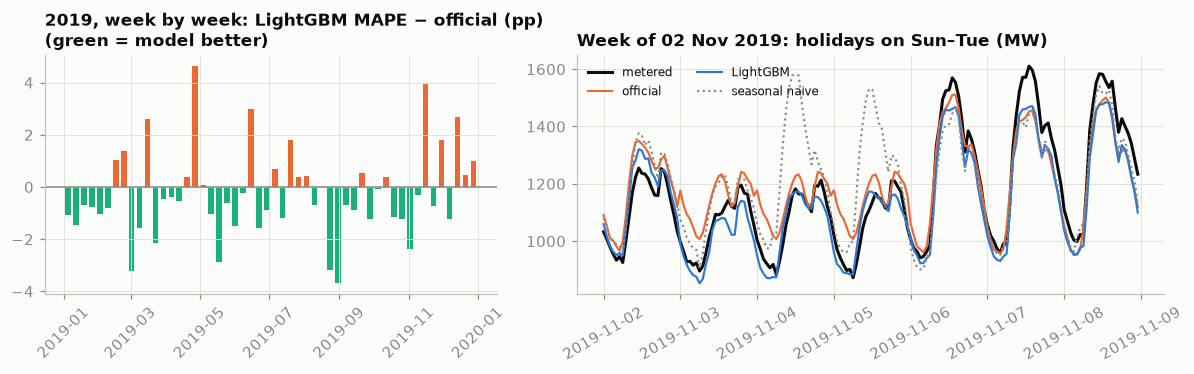

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
dd = (w_mod.mape - w_off.mape) * 100
ax.bar(dd.index, dd.values, width=5, color=[SERIES[2] if v < 0 else SERIES[1] for v in dd.values])
ax.axhline(0, color=MUTED, lw=1)
ax.set_title("2019, week by week: LightGBM MAPE − official (pp)\n(green = model better)"); ax.tick_params(axis="x", rotation=45)
ax = axes[1]
SHOW = pd.Timestamp("2019-11-02")
s = df.week == SHOW
ax.plot(df.index[s], y[s], color=INK, lw=2, label="metered")
for (k, color) in zip(["official", "LightGBM", "seasonal naive"], [SERIES[1], SERIES[0], MUTED]):
    ax.plot(df.index[s], pred[k][s.values], color=color, lw=1.4, ls="-" if k != "seasonal naive" else ":", label=k)
ax.set_title(f"Week of {SHOW:%d %b %Y}: holidays on Sun–Tue (MW)"); ax.legend(fontsize=8, ncol=2)
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
print(f"week of {SHOW:%d %b %Y}: MAPE " + " · ".join(f"{k} {weekly(p, [SHOW]).mape.iloc[0]:.2%}" for k, p in pred.items()))

**On average, LightGBM's MAPE is lower in 2019, but not significantly**: 4.21 % against 4.49 %, better in 34 of 52 weeks, with a paired 95 % interval for the gap of [−0.73, +0.18] pp. On the untouched 2019 weeks the gain cannot be told from zero. The 2017–18 weeks show a larger gap (−0.62 pp [−0.86, −0.36]), but they chose the features, so that number is optimistic and is not pooled with 2019.

**At the peak, the answer reverses.** The official forecast is better at the daily peak hour (3.65 % against 4.07 %) and gets the weekly peak about right (+8 MW); LightGBM under-forecasts it by 72 MW. A squared-error model smooths the extremes, and the official forecast leans high (bias +1.70 %). The November week shows both: the model handles the holidays better (4.30 % against 6.67 %) and still sits under the peaks.

**The knowledge-base ablation.** Four calendar contexts, same backtest. *Holiday weeks* contain a holiday or bridge day; *lag* weeks are ordinary weeks with one in their lags.

In [12]:
sp_week = df.groupby("week").special.max()
lag_hit = (sp_week.shift(2, fill_value=0) + sp_week.shift(3, fill_value=0) + sp_week.shift(4, fill_value=0)) > 0
t0 = time.time()
X_raw = build_features(clean_lags=False)
DESIGN = VAL + TEST
ablation = {"no calendar context": backtest(X_raw, TIME + RECENT + WEATHER_PROXY, DESIGN),
            "+ dataset flags (holiday, Holiday_ID, school)": backtest(X_raw, TIME + RECENT + WEATHER_PROXY + FLAGS, DESIGN),
            "+ graph context (bridges, periods, days to/from a holiday)": backtest(X_raw, MAIN, DESIGN),
            "+ lag hygiene (the main model)": pred["LightGBM"]}
groups = {"2017–18 · all": VAL, "2017–18 · holiday weeks": [w for w in VAL if sp_week[w] == 1],
          "2019 · all": TEST, "2019 · holiday weeks": [w for w in TEST if sp_week[w] == 1],
          "2019 · holiday in a lag week": [w for w in TEST if sp_week[w] == 0 and lag_hit[w]]}
abl = pd.DataFrame({name: {g: weekly(p, ws).mape.mean() for g, ws in groups.items()} for name, p in ablation.items()}).T
abl.columns = [f"{c} (n={len(groups[c])})" for c in abl.columns]
display(abl.style.format("{:.2%}"))
for a_, b_ in [("+ dataset flags (holiday, Holiday_ID, school)", "no calendar context"),
               ("+ lag hygiene (the main model)", "+ dataset flags (holiday, Holiday_ID, school)")]:
    dd_ = (weekly(ablation[a_], TEST).mape - weekly(ablation[b_], TEST).mape).values      # untouched 2019 weeks only
    bb_ = np.array([rng.choice(dd_, len(dd_)).mean() for _ in range(2000)])
    print(f"{a_.split(' (')[0]} vs {b_.split(' (')[0]}, 2019 paired: {dd_.mean():+.2%} "
          f"[{np.percentile(bb_, 2.5):+.2%}, {np.percentile(bb_, 97.5):+.2%}]")
print(f"ablation fits in {time.time() - t0:.0f}s")

,2017–18 · all (n=104),2017–18 · holiday weeks (n=24),2019 · all (n=52),2019 · holiday weeks (n=12),2019 · holiday in a lag week (n=17)
no calendar context,4.17%,5.78%,4.92%,6.54%,4.61%
"+ dataset flags (holiday, Holiday_ID, school)",3.53%,3.82%,4.16%,4.84%,4.00%
"+ graph context (bridges, periods, days to/from a holiday)",3.46%,3.75%,4.17%,4.80%,3.94%
+ lag hygiene (the main model),3.43%,3.76%,4.21%,4.98%,3.96%


+ dataset flags vs no calendar context, 2019 paired: -0.76% [-1.09%, -0.45%]
+ lag hygiene vs + dataset flags, 2019 paired: +0.05% [-0.06%, +0.17%]
ablation fits in 49s


Calendar context matters, and almost all of it is in the dataset's three flags: on 2019 they are worth −0.76 pp [−1.09, −0.45], and 6.54 % → 4.84 % in the holiday weeks. Graph context and lag hygiene helped on the design weeks (3.53 % → 3.43 %) but not on 2019: +0.05 pp [−0.06, +0.17], inside the noise. The graph earns its keep in the briefing and in facts the data lacks (E1, E2).

**What the dispatcher reads.** Task S1's LLM briefing needs context, built here deterministically: this week's forecast against last week's, the change split into the model's drivers (SHAP values, in MW), and CQ1's non-working days. They are also the golden set: a briefing citing a driver not in them fails.

In [13]:
def week_drivers(week) -> dict:
    """Facts for a dispatch briefing: this week's forecast against last week's, split into the model's own drivers."""
    prev = week - pd.Timedelta(days=7)
    m = models[max(k for k in models if k <= week)]
    out = {}
    for lab_, w in [("this", week), ("last", prev)]:
        sel = (df.week == w).values
        contrib = m.predict(X.loc[sel, MAIN], pred_contrib=True)         # SHAP values on the ratio scale
        lvl = X.loc[sel, "level_7d"].values
        out[lab_] = {"mean_mw": float(np.mean(pred["LightGBM"][sel])), "level": float(lvl.mean()),
                     "contrib": pd.DataFrame(contrib[:, :-1], columns=MAIN).mean(), "ratio": float(contrib.sum(1).mean()),
                     "peak_mw": float(np.max(pred["LightGBM"][sel])), "peak_at": df.index[sel][np.argmax(pred["LightGBM"][sel])]}
    a, b = out["this"], out["last"]
    group = {"calendar and season": FLAGS + KBCTX + ["doy"], "recent load": RECENT,
             "weather proxy": WEATHER_PROXY, "time of week": ["hour", "dow", "how", "horizon"]}
    drivers = {g: float((a["contrib"][cols] - b["contrib"][cols]).sum() * a["level"]) for g, cols in group.items()}
    drivers["level of the last 7 days"] = float((a["level"] - b["level"]) * b["ratio"])
    kb_days = [f"{str(r[0])} {r[1]}" for r in kb.query(CQ["CQ1 · non-working days in the week of 2 Nov 2019"]
               .replace("2019-11-02", f"{week:%Y-%m-%d}").replace("2019-11-08", f"{week + pd.Timedelta(days=6):%Y-%m-%d}"), initNs=NS)]
    return {"week_start": f"{week:%Y-%m-%d}", "cutoff": f"{week - pd.Timedelta(hours=GAP_HOURS + 1):%Y-%m-%d %H:%M}",
            "forecast_mean_mw": round(a["mean_mw"]), "last_week_forecast_mean_mw": round(b["mean_mw"]),
            "change_pct": round(100 * (a["mean_mw"] / b["mean_mw"] - 1), 1), "forecast_peak_mw": round(a["peak_mw"]),
            "forecast_peak_at": f"{a['peak_at']:%a %H:%M}", "drivers_mw": {k: round(v) for k, v in drivers.items()},
            "non_working_days": kb_days, "school_in_session": bool(days.loc[week, "school"]),
            "model": f"LightGBM, trained to {max(k for k in models if k <= week) - pd.Timedelta(hours=GAP_HOURS + 1):%Y-%m-%d %H:%M}"}

facts = week_drivers(SHOW)
print(json.dumps(facts, indent=1, ensure_ascii=False))
top = sorted(facts["drivers_mw"].items(), key=lambda kv: -abs(kv[1]))[:2]
print(f"\nTemplate briefing (the S1 baseline): forecast for the week of {facts['week_start']} averages "
      f"{facts['forecast_mean_mw']:,} MW, {facts['change_pct']:+.1f} % on last week's forecast; peak {facts['forecast_peak_mw']:,} MW "
      f"on {facts['forecast_peak_at']}. Main drivers: " + "; ".join(f"{k} {v:+d} MW" for k, v in top) +
      f". Non-working days: {', '.join(facts['non_working_days']) or 'none'}.")

{
 "week_start": "2019-11-02",
 "cutoff": "2019-10-29 23:00",
 "forecast_mean_mw": 1131,
 "last_week_forecast_mean_mw": 1208,
 "change_pct": -6.4,
 "forecast_peak_mw": 1485,
 "forecast_peak_at": "Fri 13:00",
 "drivers_mw": {
  "calendar and season": -78,
  "recent load": -45,
  "weather proxy": -1,
  "time of week": 2,
  "level of the last 7 days": 43
 },
 "non_working_days": [
  "2019-11-03 Separation from Colombia",
  "2019-11-04 Flag Day",
  "2019-11-05 Colón Day"
 ],
 "school_in_session": true,
 "model": "LightGBM, trained to 2019-10-01 23:00"
}

Template briefing (the S1 baseline): forecast for the week of 2019-11-02 averages 1,131 MW, -6.4 % on last week's forecast; peak 1,485 MW on Fri 13:00. Main drivers: calendar and season -78 MW; recent load -45 MW. Non-working days: 2019-11-03 Separation from Colombia, 2019-11-04 Flag Day, 2019-11-05 Colón Day.


## 5 · The operating point: pricing a short MW and a long MW

*Part B · Given model · package `cost_per_week`; C3 asks you to own the short and long prices.*

MAPE treats a megawatt-hour too high and too low alike; the dispatch desk does not. Being **short** means emergency thermal units or spot imports; being **long**, generation committed and not used. At $150 and $40 per MWh (assumptions: task C3), the cheapest plan covers about 79 % of hours. Each forecaster gets one **uplift**, chosen on the validation weeks and frozen for 2019.

newsvendor check: the cost ratio implies covering 79% of hours


,uplift chosen on 2017–18,"2017–18 cost, with uplift (k$/week)","2019 cost, no uplift (k$/week)","2019 cost, with uplift (k$/week)",2019 MAPE with uplift,"hours short, with uplift"
official,+2.4%,531,684,618,5.61%,21%
seasonal naive,+4.0%,625,926,729,6.53%,23%
LightGBM,+4.0%,470,899,624,5.23%,26%


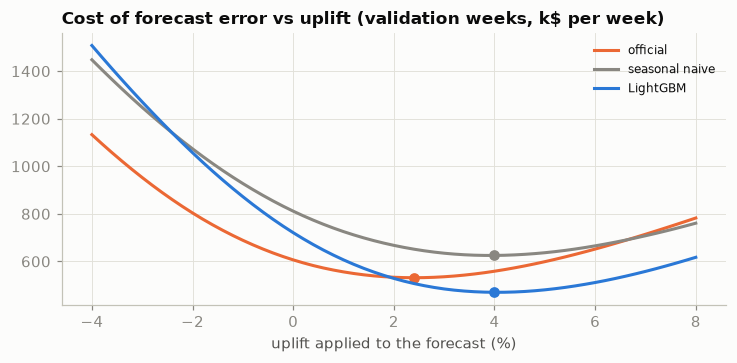

In [14]:
def cost_per_week(p, target_weeks, uplift=0.0) -> float:
    m = df.week.isin(target_weeks).values & OK & ~np.isnan(p)
    err = y.values[m] - p[m] * (1 + uplift)                        # > 0: short (load above plan); < 0: long
    return float((COST_SHORT_USD_PER_MWH * err.clip(min=0) + COST_LONG_USD_PER_MWH * (-err).clip(min=0)).sum() / len(target_weeks))

UPLIFTS = np.round(np.arange(-0.04, 0.0801, 0.002), 3)
curves = {k: np.array([cost_per_week(p, VAL, u) for u in UPLIFTS]) for k, p in pred.items()}
op = {}
for k, p in pred.items():
    u = float(UPLIFTS[curves[k].argmin()])
    m = df.week.isin(TEST).values & OK
    op[k] = {"uplift chosen on 2017–18": u, "2017–18 cost, with uplift (k$/week)": curves[k].min() / 1e3,
             "2019 cost, no uplift (k$/week)": cost_per_week(p, TEST) / 1e3,
             "2019 cost, with uplift (k$/week)": cost_per_week(p, TEST, u) / 1e3,
             "2019 MAPE with uplift": weekly(p * (1 + u), TEST).mape.mean(),
             "hours short, with uplift": float((y.values[m] > p[m] * (1 + u)).mean())}
op = pd.DataFrame(op).T

fig, ax = plt.subplots(figsize=(6.8, 3.4))
for (k, cv), color in zip(curves.items(), [SERIES[1], MUTED, SERIES[0]]):
    ax.plot(UPLIFTS * 100, cv / 1e3, lw=2, color=color, label=k)
    ax.plot([op.loc[k, "uplift chosen on 2017–18"] * 100], [cv.min() / 1e3], "o", color=color, ms=6)
ax.set_title("Cost of forecast error vs uplift (validation weeks, k$ per week)"); ax.set_xlabel("uplift applied to the forecast (%)")
ax.legend(fontsize=8); plt.tight_layout()
print(f"newsvendor check: the cost ratio implies covering {COST_SHORT_USD_PER_MWH / (COST_SHORT_USD_PER_MWH + COST_LONG_USD_PER_MWH):.0%} of hours")
op.style.format({"uplift chosen on 2017–18": "{:+.1%}", "2017–18 cost, with uplift (k$/week)": "{:,.0f}",
                 "2019 cost, no uplift (k$/week)": "{:,.0f}",
                 "2019 cost, with uplift (k$/week)": "{:,.0f}", "2019 MAPE with uplift": "{:.2%}", "hours short, with uplift": "{:.0%}"})

**Unadjusted, LightGBM's lower MAPE is a cost loss**: its under-forecasts cost 899 k$ a week in 2019 against 684 k$ for the official forecast, whose +1.70 % bias already works as a hedge. **Priced and uplifted**, the model looked cheaper on the validation weeks (470 against 531 k$ a week), but in 2019 the two cost 624 and 618 k$: a tie. On cost the model has not yet earned its place: price it (task C3) and keep the official forecast as the reference run (task C5). The dollar levels rest on two assumed prices: compare forecasters, not totals.

## 6 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

Four ways a careless notebook would report a better number than the operator could ever get, each measured. (Quirk 3's zero-coded hours would be a fifth, but they fall in 2016, before the evaluation window.)

In [15]:
t0 = time.time()
trap_rows = []
# Trap 1 — the weather that happened
X_act = build_features(weather="actual")
p_act = backtest(X_act, MAIN, TEST)
trap_rows.append(("Trap 1 · actual weather of the target hour", summary(p_act, TEST, "")["MAPE"], res_test.loc["LightGBM", "MAPE"]))
# Trap 2 — the 72-hour gap ignored: data up to Friday 23:00
X_gap0 = build_features(gap_hours=0)
p_gap0 = backtest(X_gap0, MAIN, TEST, gap_hours=0)
trap_rows.append(("Trap 2 · no 72-hour gap (LightGBM)", summary(p_gap0, TEST, "")["MAPE"], res_test.loc["LightGBM", "MAPE"]))
trap_rows.append(("Trap 2 · no 72-hour gap (seasonal naive)", summary(seasonal_naive(gap_hours=0), TEST, "")["MAPE"],
                  res_test.loc["seasonal naive", "MAPE"]))
# Trap 3 — random cross-validation over hours of 2015–2018
rows = np.flatnonzero((df.index >= TRAIN_START) & (df.index < TEST_START) & OK)
p_cv = np.full(len(df), np.nan)
for a, b in KFold(5, shuffle=True, random_state=SEED).split(rows):
    m = lgb.LGBMRegressor(**LGB_PARAMS).fit(X.iloc[rows[a]][MAIN], y.iloc[rows[a]] / X.level_7d.iloc[rows[a]])
    p_cv[rows[b]] = m.predict(X.iloc[rows[b]][MAIN]) * X.level_7d.iloc[rows[b]].values
cv_weeks = [w for w in weeks if VALID_START <= w < TEST_START]
trap_rows.append(("Trap 3 · random 5-fold CV, scored on 2017–18 hours", summary(p_cv, cv_weeks, "")["MAPE"],
                  summary(pred["LightGBM"], VAL, "")["MAPE"]))
# Trap 4 — holidays copied from the lag weeks
lagw = groups["2019 · holiday in a lag week"]
naive_raw = seasonal_naive(clean_lags=False)
trap_rows.append(("Trap 4 · holiday in the lags (seasonal naive, all 2019)", summary(naive_raw, TEST, "")["MAPE"],
                  res_test.loc["seasonal naive", "MAPE"]))
trap_rows.append(("Trap 4 · holiday in the lags (seasonal naive, affected weeks)", summary(naive_raw, lagw, "")["MAPE"],
                  summary(pred["seasonal naive"], lagw, "")["MAPE"]))
trap_rows.append(("Trap 4 · holiday in the lags (LightGBM, affected weeks)",
                  summary(ablation["+ graph context (bridges, periods, days to/from a holiday)"], lagw, "")["MAPE"],
                  summary(pred["LightGBM"], lagw, "")["MAPE"]))
traps = pd.DataFrame(trap_rows, columns=["trap", "careless MAPE", "honest MAPE"]).set_index("trap")
traps["careless − honest (pp)"] = (traps["careless MAPE"] - traps["honest MAPE"]) * 100
off19 = res_test.loc["official", "MAPE"]
lgb19 = res_test.loc["LightGBM", "MAPE"]
print(f"LightGBM's lead over the seasonal naive in 2019: {summary(naive_raw, TEST, '')['MAPE'] - lgb19:.2%} against the careless "
      f"naive, {res_test.loc['seasonal naive', 'MAPE'] - lgb19:.2%} against the fixed one")
print(f"official forecast, 2019: {off19:.2%} · with actual weather the model's margin over it looks like "
      f"{off19 - traps.iloc[0, 0]:.2%} instead of {off19 - traps.iloc[0, 1]:.2%} · trap fits in {time.time() - t0:.0f}s")
traps.style.format({"careless MAPE": "{:.2%}", "honest MAPE": "{:.2%}", "careless − honest (pp)": "{:+.2f}"})

LightGBM's lead over the seasonal naive in 2019: 1.31% against the careless naive, 0.89% against the fixed one
official forecast, 2019: 4.49% · with actual weather the model's margin over it looks like 0.70% instead of 0.27% · trap fits in 22s


,careless MAPE,honest MAPE,careless − honest (pp)
trap,,,
Trap 1 · actual weather of the target hour,3.78%,4.21%,-0.43
Trap 2 · no 72-hour gap (LightGBM),3.85%,4.21%,-0.36
Trap 2 · no 72-hour gap (seasonal naive),5.00%,5.10%,-0.10
"Trap 3 · random 5-fold CV, scored on 2017–18 hours",2.11%,3.43%,-1.32
"Trap 4 · holiday in the lags (seasonal naive, all 2019)",5.53%,5.10%,+0.42
"Trap 4 · holiday in the lags (seasonal naive, affected weeks)",4.74%,4.42%,+0.31
"Trap 4 · holiday in the lags (LightGBM, affected weeks)",3.94%,3.96%,-0.01


**Trap 1 — the weather that happened.** With each hour's actual weather, as in the packaged test sheets, 2019 MAPE drops from 4.21 % to 3.78 %, and the margin over the official forecast looks like 0.70 pp instead of 0.27. Test with archived weather forecasts (E3).

**Trap 2 — ignoring the 72-hour gap.** With data up to Friday 23:00, MAPE falls to 3.85 %; the seasonal naive barely moves (5.00 % against 5.10 %). Our untested hypothesis: the gap mostly hurts the *level*, since the seven days before Friday already know the week ahead (C1: restore only the level features).

**Trap 3 — random cross-validation.** Shuffle the 2015–2018 hours into five folds and the model scores 2.11 % on the 2017–2018 hours; forecast forward, they score 3.43 %. Neighbouring hours share a level and a temperature.

**Trap 4 — holidays copied from the lags.** A seasonal naive that copies a holiday into an ordinary week two weeks later scores 5.53 % in 2019, against 5.10 % with lag hygiene (4.74 % against 4.42 % in the 17 affected weeks). A weak benchmark flatters the challenger: LightGBM's lead shrinks from 1.31 to 0.89 pp once the naive is fixed. LightGBM itself barely notices (3.94 % against 3.96 %); our hypothesis is that *days since a holiday* tells it which lags to discount (test it by dropping that feature).

# Part C — Productionise it

*Sections 7–10: this is your assignment.*

## 7 · After deployment: growth, a pandemic, and the operator's head start

*Part C · Productionise · what your monitoring plan must catch; reuse `seen_residual` for the seen-hours alarm (C5).*

Two drifts run through this data: slow growth, absorbed by the ratio target, and the March 2020 shock. We replay January–June 2020 as production, adding a model frozen at end-2018. By Tuesday's cutoff the first 96 hours of the running week are metered, so the model's error on them is a signal available *before* the next forecast goes out.

In [16]:
frozen_key = TEST[0]                                       # the model trained to the cutoff before the first 2019 week, never refitted
sel = df.week.isin(TEST + STREAM).values
p_frozen = np.full(len(df), np.nan)
p_frozen[sel] = models[frozen_key].predict(X.loc[sel, MAIN]) * X.loc[sel, "level_7d"].values
pred_drift = {**pred, "LightGBM, frozen at end-2018": p_frozen}
BREAK = pd.Timestamp("2020-03-14")
phases = {"2019": TEST, "2020 before 14 Mar": [w for w in STREAM if w < BREAK], "2020 from 14 Mar": [w for w in STREAM if w >= BREAK]}
drift = pd.DataFrame({f"{ph} · {met}": {k: summary(p, ws, k)[met] for k, p in pred_drift.items()}
                      for ph, ws in phases.items() for met in ["MAPE", "bias"]})
display(drift.style.format({c: ("{:.2%}" if c.endswith("MAPE") else "{:+.1%}") for c in drift.columns}))

# Monitoring signal available AT the cutoff: the model's error on the hours already metered (Sat–Tue of the running week)
def seen_residual(p) -> pd.Series:
    out = {}
    for w in ALL:
        cut = w - pd.Timedelta(hours=GAP_HOURS + 1)
        m = (df.index > cut - pd.Timedelta(hours=96)) & (df.index <= cut) & OK & ~np.isnan(p)
        out[w] = float((p[m].sum() / y.values[m].sum()) - 1) if m.sum() else np.nan
    return pd.Series(out)
resid = seen_residual(pred["LightGBM"])
alarm = resid.abs() > ALARM_RESIDUAL
print(f"alarm (|error on the 96 hours seen at the cutoff| > {ALARM_RESIDUAL:.0%}): fired in {int(alarm[VAL].sum())} of {len(VAL)} "
      f"validation weeks, {int(alarm[TEST].sum())} of {len(TEST)} test weeks; in 2020 first at the cutoff for the week of "
      f"{next(w for w in STREAM if alarm[w]):%d %b}")
print("2020 cutoffs with an alarm (week of):", ", ".join(f"{w:%d %b} ({resid[w]:+.1%})" for w in STREAM if alarm[w]))
around = [w for w in STREAM if BREAK - pd.Timedelta(days=7) <= w <= BREAK + pd.Timedelta(days=21)]
print("weekly bias around the break: " + " · ".join(
    f"{w:%d %b}: official {weekly(pred['official'], [w]).bias.iloc[0]:+.1%}, LightGBM {weekly(pred['LightGBM'], [w]).bias.iloc[0]:+.1%}"
    for w in around))
corr = pred["LightGBM"].copy()
for w in ALL:                                             # the action the alarm could trigger: rescale by the seen-hours error
    if alarm[w]:
        corr[(df.week == w).values] /= (1 + resid[w])
for ph in ["2020 before 14 Mar", "2020 from 14 Mar"]:
    m_, lo, hi, wins, n = gap_ci(phases[ph])
    print(f"{ph}: LightGBM − official {m_:+.2%} [{lo:+.2%}, {hi:+.2%}], better in {wins} of {n} weeks")
print("rescale-on-alarm, MAPE by phase: " + " · ".join(
    f"{ph} {weekly(pred['LightGBM'], ws).mape.mean():.2%} → {weekly(corr, ws).mape.mean():.2%}" for ph, ws in phases.items()))
print("            … in the weeks it fired after the break: " + " · ".join(
    f"{w:%d %b} {weekly(pred['LightGBM'], [w]).mape.iloc[0]:.1%} → {weekly(corr, [w]).mape.iloc[0]:.1%}"
    for w in STREAM if alarm[w] and w >= BREAK))

,2019 · MAPE,2019 · bias,2020 before 14 Mar · MAPE,2020 before 14 Mar · bias,2020 from 14 Mar · MAPE,2020 from 14 Mar · bias
official,4.49%,+1.7%,5.43%,+0.4%,5.51%,+2.5%
seasonal naive,5.10%,+0.7%,6.71%,+1.0%,5.94%,+1.5%
LightGBM,4.21%,-0.5%,4.29%,+0.5%,7.32%,+3.8%
"LightGBM, frozen at end-2018",4.06%,-0.5%,5.10%,-0.1%,7.09%,+3.5%


alarm (|error on the 96 hours seen at the cutoff| > 5%): fired in 9 of 104 validation weeks, 8 of 52 test weeks; in 2020 first at the cutoff for the week of 25 Jan
2020 cutoffs with an alarm (week of): 25 Jan (-11.6%), 01 Feb (+5.5%), 28 Mar (+16.5%), 04 Apr (+14.8%), 18 Apr (+9.7%), 25 Apr (+5.2%)
weekly bias around the break: 07 Mar: official +2.5%, LightGBM +2.0% · 14 Mar: official +6.1%, LightGBM +6.3% · 21 Mar: official +11.9%, LightGBM +19.9% · 28 Mar: official -2.8%, LightGBM +18.0% · 04 Apr: official +0.3%, LightGBM +0.1%
2020 before 14 Mar: LightGBM − official -1.14% [-3.09%, +0.06%], better in 7 of 10 weeks


2020 from 14 Mar: LightGBM − official +1.81% [-0.14%, +3.96%], better in 5 of 15 weeks
rescale-on-alarm, MAPE by phase: 2019 4.21% → 4.44% · 2020 before 14 Mar 4.29% → 5.76% · 2020 from 14 Mar 7.32% → 7.33%


            … in the weeks it fired after the break: 28 Mar 17.8% → 9.3% · 04 Apr 7.9% → 13.0% · 18 Apr 5.3% → 5.9% · 25 Apr 3.6% → 6.6%


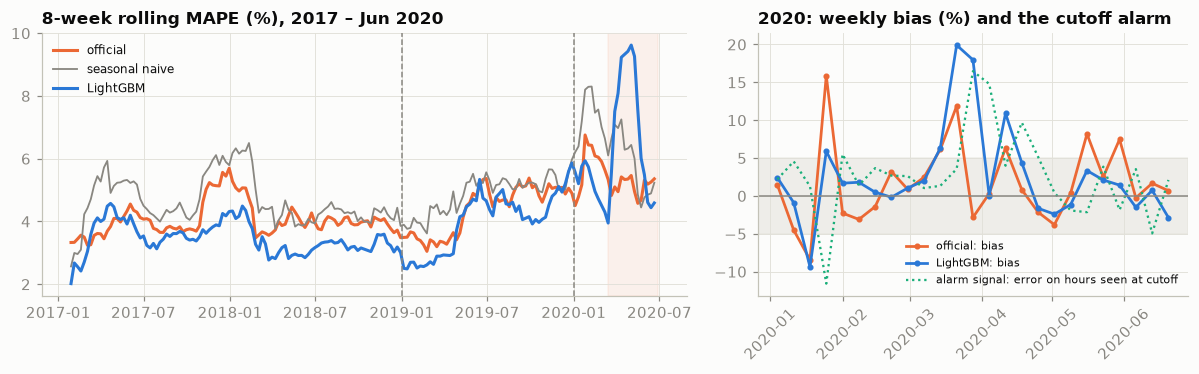

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
for (k, color) in zip(["official", "seasonal naive", "LightGBM"], [SERIES[1], MUTED, SERIES[0]]):
    w = weekly(pred[k], ALL).mape.rolling(8, min_periods=4).mean() * 100
    ax.plot(w.index, w.values, lw=2 if k != "seasonal naive" else 1.2, color=color, label=k)
for x in [TEST_START, STREAM_START]:
    ax.axvline(x, color=MUTED, ls="--", lw=1)
ax.axvspan(BREAK, STREAM[-1] + pd.Timedelta(days=7), color=SERIES[1], alpha=0.08)
ax.set_title("8-week rolling MAPE (%), 2017 – Jun 2020"); ax.legend(fontsize=8, loc="upper left")
ax = axes[1]
ws = STREAM
for (k, color) in zip(["official", "LightGBM"], [SERIES[1], SERIES[0]]):
    b = weekly(pred[k], ws).bias * 100
    ax.plot(b.index, b.values, "-o", ms=3, lw=1.8, color=color, label=f"{k}: bias")
ax.plot(resid[ws].index, resid[ws].values * 100, ":", lw=1.5, color=SERIES[2], label="alarm signal: error on hours seen at cutoff")
ax.axhspan(-ALARM_RESIDUAL * 100, ALARM_RESIDUAL * 100, color=GRID, alpha=0.5)
ax.axhline(0, color=MUTED, lw=1)
ax.set_title("2020: weekly bias (%) and the cutoff alarm"); ax.legend(fontsize=7); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()

Three lessons for the monitoring plan.

*Growth is not the problem.* Frozen at the end of 2018, the model scores 4.06 % in 2019, no worse than the quarterly refits (4.21 %): the level features carry the growth (S3).

*The shock is.* Before 14 March 2020 LightGBM's MAPE was lower than the official forecast's (4.29 % against 5.43 %, gap −1.14 pp [−3.09, +0.06] over 10 weeks); from 14 March it was higher (7.32 % against 5.51 %, +1.81 pp [−0.14, +3.96] over 15 weeks). Neither interval excludes zero on so few weeks, but the direction flipped. For the week of 28 March, forecast on Tuesday 24 March, the model was 18.0 % too high and the operator 2.8 % too low. The data cannot say why; something the planners knew and no column records is the obvious candidate (E2).

*Alarms are for people.* The seen-hours alarm fired in 9 of 104 validation and 8 of 52 test weeks; in 2020 for 25 January and 1 February, not for 21 March (still within 5 %), then for 28 March (+16.5 %) and three later weeks. Rescaling automatically by that error cut the first lockdown week's error (17.8 % → 9.3 %) and worsened the next (7.9 % → 13.0 %), counting the drop twice once the level features had caught up. The alarm should send the week to the dispatch engineer (C5).

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The card's plan, updated with what this notebook measured: starting values, not targets to copy.

| Spine | In this project — after this notebook |
|---|---|
| Package and container (S02–S03) | `src/load_forecast/` (`protocol.py`, `features.py` with the as-of assertions, `calendar_kb.py`, `backtest.py`); a weekly batch job after the Tuesday cutoff; `GET /forecast?week=` serves the stored 168 values. |
| Monitoring (S04) | Weekly MAPE, peak-hour MAPE and bias against the official forecast; at each cutoff, the error on the 96 metered hours (alarm at ±5 %); gaps, collapsed and zero-coded hours. |
| CI/CD gate (S05) | Rerun the 2019 backtest on fingerprinted raw files (`ef52f68fc898…`, `002a40a01b7d…`); fail unless MAPE ≤ the official 4.49 % **and** peak-hour MAPE ≤ the official 3.65 %. Today's model passes the first on its point estimate only (4.21 %; the 2019 gap's interval [−0.73, +0.18] pp includes zero) and fails the second (4.07 %). |
| MLflow tracking and registry (S06) | Model family, cutoff rule (`GAP_HOURS = 72`), graph version, features, cadence, uplift, metrics per period; the official forecast as a reference run; `champion` and `challenger`. |
| Offline / online training and serving | Offline weekly batch. Frozen at end-2018, the model matched quarterly refits in 2019 (4.06 % against 4.21 %): cadence is an ADR (S3). |
| Data and model drift | Load +2.0 to +3.1 % a year, absorbed by the ratio target. Apr–Jun 2020: −22.9 % at midday, −6.0 % at night against 2019. From 14 Mar 2020, MAPE 7.32 % against the official 5.51 %. |
| Knowledge base and context (S07–S09) | 768-triple graph, four SHACL shapes, three CQs; R1 adds 15 bridge days, R2 44 period days. Ablation on 2019: flags −0.76 pp [−1.09, −0.45]; graph context and hygiene +0.05 pp [−0.06, +0.17]. |
| GenAI and context engineering (S10–S11) | Briefing from the facts dictionary only (forecast, change, SHAP drivers, CQ1 days), which is also the golden set. |
| Governance | Is a weekly forecast a *safety component* in the supply of electricity (AI Act, Annex III, point 2)? Human sign-off on every plan; CC BY 4.0 attribution; no personal data. |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap.** Turn the as-of assertions into `tests/test_protocol.py` (fail on any input read after the Tuesday cutoff); refuse zero-coded forecast hours and collapsed load; use no weather input that did not exist before the cutoff; report honest 2019 numbers with intervals, never pooled with the design weeks.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary the short and long prices (say 80–400 and 20–80 $/MWh) and allow separate peak and off-peak uplifts; show how the choice and the 2019 cost move; write the ADR, naming who signs off the prices.
- **C4 — Package and gate.** Package protocol, features and backtest (Session 02), containerise the weekly job (Session 03), and gate CI on the fingerprinted 2019 backtest: MAPE and peak-hour MAPE no worse than the official forecast's (Session 05).
- **C5 — Register, document, monitor.** MLflow runs with the cutoff rule, graph version and fingerprints; `champion` and `challenger` aliases; a model card (real data, CC BY, the quirks, March 2020, cost assumptions); a monitoring plan naming the seen-hours alarm's owner and response, the retraining trigger and the rollback to the official forecast (Sessions 04 and 06).

### Extension

- **E1 — Knowledge-base ablation.** Extend the graph (regional holidays, breaks within terms), validate with SHACL, and rerun the ablation with paired intervals on 2019 and three seeds: does graph context earn a place in the model or only in the briefing (Sessions 07–09)?
- **E2 — An events layer.** Model the days the calendar cannot explain as dated events with a source, entered *before* the cutoff; measure the effect on spring 2020 and say who enters them.
- **E3 — Weather done right.** Use an archived weather forecast, or simulate one by adding forecast-like error to the actual weather (labelled as such), and place it between persistence and Trap 1's oracle.
- **E4 — Regulatory position.** Annex III, point 2 of the AI Act lists AI systems *intended to be used as safety components in the management and operation of critical digital infrastructure, road traffic, or in the supply of water, gas, heating or electricity*. Is a weekly load forecast a safety component (Article 3(14)), or a planning aid whose failures reserve and the dispatcher catch? Could Article 6(3)'s derogation for preparatory tasks apply? Write your reading as an ADR, with the obligations if yes. Whether the Act applies at all depends on its territorial scope (Article 2(1)); our reading is that a Panamanian operator using it in Panama is outside it.

### Stretch

- **S1 — Dispatch briefing with an LLM.** From the Section 4 facts alone, generate the briefing with a versioned prompt and structured output; build a 20-week golden set (holiday, lockdown, ordinary weeks); score factual consistency and refusal to invent causes; test a prompt injection in an event note; report cost per briefing (Sessions 10–11).
- **S2 — Intra-day serving.** Serve the given model day-ahead by re-running its own code with a shorter cutoff as metered load streams in (no new features or learner); state the latency budget and cost per forecast, and how much of March 2020 it would have caught.
- **S3 — Retraining policy.** Compare frozen, quarterly, monthly and alarm-triggered retraining over 2017–2020 (accuracy, peak error, cost, compute) and recommend one in an ADR.

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Repository in the Session 02 layout; fresh-clone test passes; `data/` not committed; CC BY 4.0 attribution and the protocol (Saturday weeks, Tuesday 23:00 cutoff) in `README.md`
- [ ] Protocol and as-of tests; the four traps fixed with evidence; zero-coded and collapsed hours refused
- [ ] Four metrics against the official forecast on the same hours, with paired intervals; operating point with its ADR
- [ ] CI gate on fingerprinted 2019 weeks; registered model and model card; monitoring plan with the alarm's owner
- [ ] Calendar graph with SHACL shapes and the ablation; briefing golden set (if S1)
- [ ] One-page recommendation to the dispatch manager (replace, support or keep the official forecast) with the AI Act reading
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `openpyxl`, `scikit-learn`, `lightgbm`, `matplotlib`, `rdflib`, `pyshacl`, `kagglehub` (pinned in `requirements.txt`). No LLM is needed for the baseline.
- Aguilar Madrid, E. (2021). *Short-term electricity load forecasting (Panama case study)*. Mendeley Data. doi:10.17632/byx7sztj59.1 · Aguilar Madrid, E., Antonio, N. (2021). Short-term electricity load forecasting with machine learning. *Information*, 12(2), 50.
- Hyndman, R. J., Athanasopoulos, G. (2021). *Forecasting: Principles and Practice*, 3rd ed., Ch. 5 · Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy. *IJF* 16(4) · Hong, T., Fan, S. (2016). Probabilistic electric load forecasting. *IJF* 32(3).
- Ke, G. et al. (2017). *LightGBM.* NeurIPS · Lundberg, S. M., Lee, S.-I. (2017). *A unified approach to interpreting model predictions.* NeurIPS · W3C (2017). *SHACL* · Regulation (EU) 2024/1689 (AI Act).

In [18]:
print(f"pandas {pd.__version__} · numpy {np.__version__} · lightgbm {lgb.__version__} · scikit-learn {sklearn.__version__} · "
      f"rdflib {rdflib.__version__}")
print(f"notebook finished · total wall time {time.time() - T_START:.0f}s")

pandas 3.1.0 · numpy 2.5.4 · lightgbm 4.7.0 · scikit-learn 1.9.1 · rdflib 7.6.0
notebook finished · total wall time 101s
